# Permanente evaluatie - vaardigheidstoets 2
16 november - 2ITAI - AP Hogeschool

## Opgave

Laad de volgende dataset in: de wine dataset via `from sklearn.datasets import load_wine` - deze dataset bevat informatie over wijnen, en 3 labels (class 0, class 1, class 2, hier is verder niets over gekend). Die labels hebben ze helemaal op het eind kort nodig.

Pas op deze dataset een datareductietechniek toe, en cluster vervolgens de gereduceerde dataset zo goed mogelijk. Zorg voor preprocessing waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom**. Vergelijk op het einde of de labels van je clusteringalgoritme overeenkomen met de originele labels `wine.target`, met behulp van een confusion matrix waarbij je de labels meegeeft en de clusters (clusters zijn het resultaat van `fit_predict()`). Trek hier conclusies uit en noteer deze in de notebook.

### Inleveren:
- Hernoem je bestand naar **PE2-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laadt dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd.

### Indicatieve puntenverdeling /20
- goede algoritmes: 2 keer 4 ptn
- goede beschrijving over keuze van deze algoritmes: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

## Meer info over de dataset
Te verkrijgen via 
```python
wine = load_wine()
print(wine.DESCR)
```

# Oplossing

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

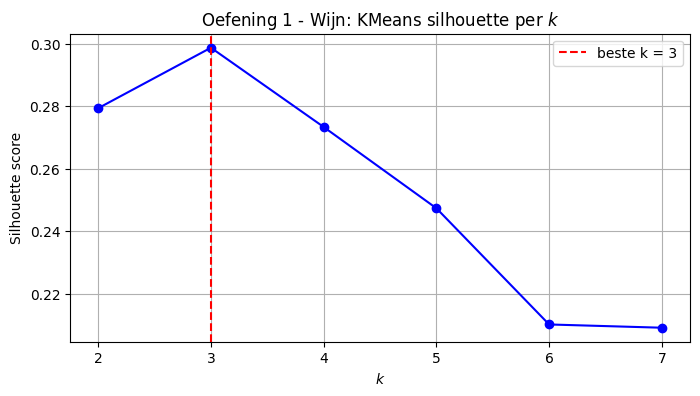

DBS -> best eps = 9 met sample size 26 met een silhouette score van 0.26324995567650267


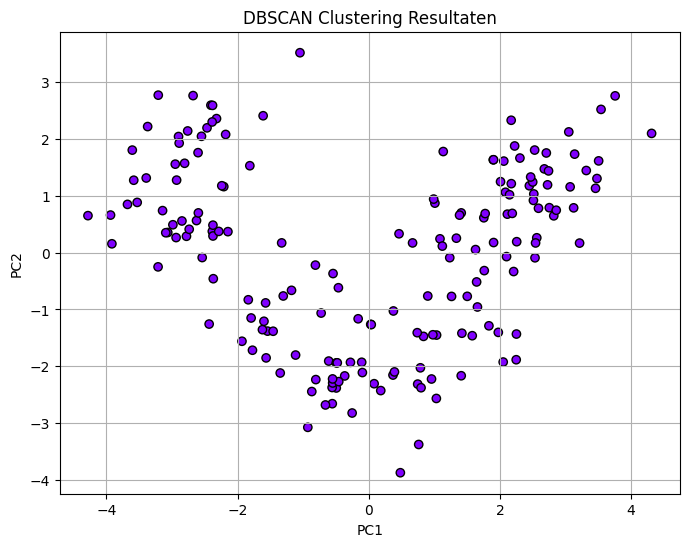

de confusion matrix van de dbs:	
[[59  0  0]
 [71  0  0]
 [48  0  0]]


In [3]:
# Code
import pandas as pd
import numpy as np
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

wine = load_wine()
X = wine.data
print(wine.DESCR)

#eerst scale ik de data omdat anders tijdens dimensiereductie sommige waarden worden weggegooid
scaler = StandardScaler()
wine_scaled = scaler.fit_transform(X)

#nu doe ik dimensie reductie en ik doe de standaard 0.95 wat ervoor zorgt dat de dataset 95% variantie (informatie) behoud
pca = PCA(n_components=0.95)
wine_pca = pca.fit_transform(wine_scaled)

#ik probeer eerst KMEANS hier de imports
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score

k_range_wine = list(range(2, 8)) #range zit rond 2-8 omdat ik weet dat er maar 3 soorten wijn zijn maar ik wil wel toch meerdere opties zien
sil_scores_wine = []
best_sil = -1.0
best_k_wine = None
beste_labels =None
for k in k_range_wine:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(wine_pca)
    sil = silhouette_score(wine_pca, kmeans.labels_)
    sil_scores_wine.append(sil)
    if sil > best_sil:
        best_sil = sil
        best_k_wine = k
        beste_labels = kmeans.labels_
silhouette_wine = best_sil
#confusion matrix voor Kmeans
print("de confusion matrix van de kmeans:\t")
print(confusion_matrix(wine.target,beste_labels))
print(f"Kmeans -> best K = {best_k_wine}  met een silhouette score van {best_sil}")

# Silhouette per k (elbow)
plt.figure(figsize=(8, 4))
plt.plot(k_range_wine, sil_scores_wine, 'bo-')
plt.axvline(best_k_wine, color='red', linestyle='--', label=f'beste k = {best_k_wine}')
plt.xlabel('$k$')
plt.ylabel('Silhouette score')
plt.title('Oefening 1 - Wijn: KMeans silhouette per $k$')
plt.grid()
plt.legend()
plt.show()

#nu probeer ik DBScan en ik vergelijk
#de data die ik gebruik is dezelfde geschaalde en gereduceerde data die ik hierboven heb gebruikt dus dit moet ik niet opnieuw doen
dbs_wine_sil = -1
dbs_wine_best_e = None
dbs_wine_best_samp = None
#de buitenste loop is voor de epsilon en de binnenste voor de min_samples
for e in range(1,10):
    for m in range(1,30,5): 
        dbs = DBSCAN(eps=e,min_samples=m).fit(wine_pca) #fit_predict() lukt mij precies niet omdat ik het dan zou moeten reshapen en ik ben daar niet 100% vertrouwd in
        try: # ik gebruik hier een try except omdat als je als cluster 1 of minder krijgt dan heb je een valueerror en krijg je een foutmelding, dit zorgt ervoor dat de loop niet stopt
            sil = silhouette_score(wine_pca,dbs.labels_)
            if sil > dbs_wine_sil:
                dbs_wine_sil = sil
                dbs_wine_best_e = e
                dbs_wine_best_samp = m 
        except ValueError:
            continue
print(f"DBS -> best eps = {e} met sample size {m} met een silhouette score van {dbs_wine_sil}")
#plot gemaakt met hulp van de toegelaten chatbot
dbs = DBSCAN(eps=9, min_samples=5).fit(wine_pca)
plt.figure(figsize=(8, 6))
plt.scatter(wine_pca[:, 0], wine_pca[:, 1], c=dbs.labels_, cmap=plt.cm.rainbow, marker='o', edgecolor='black')
plt.title('DBSCAN Clustering Resultaten')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.grid(True)
plt.show()
#de confusion matrix

print("de confusion matrix van de dbs:\t")
print(confusion_matrix(wine.target,dbs.labels_))

#als ik ze allebei vergelijk dan doet oftewel Kmeans het veel beter of hij overfit. Maar ze zitten allebei wel dichtbij hetzelfde antwoord. 
#bij kmeans is de beste k = 3 met een silhouette score van ongeveer 0.29(wat logisch is want er zijn 3 soorten wijn)
#en bij dbscan zit hij rond de  0.26(wat niet ver is van 0.29) bij een epsilon van 9